In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [5]:
#upload dataset
data=pd.read_csv("/content/balance-scale.csv")
#Display the first five records
print("First five records:")
print(data.head())
print("Last few records")
print(data.tail())

First five records:
  Class  L-Weight  L-Distance  R-Weight  R-Distance
0     B         1           1         1           1
1     R         1           1         1           2
2     R         1           1         1           3
3     R         1           1         1           4
4     R         1           1         1           5
Last few records
    Class  L-Weight  L-Distance  R-Weight  R-Distance
620     L         5           5         5           1
621     L         5           5         5           2
622     L         5           5         5           3
623     L         5           5         5           4
624     B         5           5         5           5


In [6]:
X=data.iloc[:,1:5]
Y=data.iloc[:,0]


In [7]:
#Display the feature
print("\n Input features:")
print(X.head())
print("\n Target features:")
print(Y.head())


 Input features:
   L-Weight  L-Distance  R-Weight  R-Distance
0         1           1         1           1
1         1           1         1           2
2         1           1         1           3
3         1           1         1           4
4         1           1         1           5

 Target features:
0    B
1    R
2    R
3    R
4    R
Name: Class, dtype: object


In [8]:
#Display the class distribution
class_count=Y.value_counts()
class_count

,count
Class,
R,288
L,288
B,49


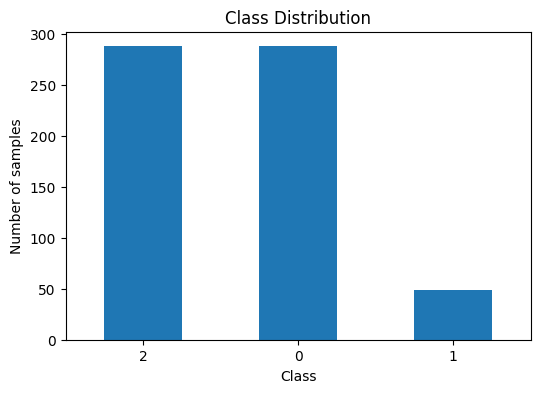

In [ ]:
plt.figure(figsize=(6,4))
class_count.plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.show()

In [9]:
X_train,X_test,Y_train,Y_test=train_test_split(
    X,
    Y,
    test_size=0.3,
    random_state=42
    )

In [10]:
model=GaussianNB()
model.fit(X_train,Y_train)

GaussianNB()

In [11]:
print("\nClass Prior P(Ci):")
print(model.class_prior_)



Class Prior P(Ci):
[0.07093822 0.47597254 0.45308924]


In [12]:
print(model.theta_)
print(model.var_)

[[3.12903226 3.         3.12903226 3.        ]
 [3.625      3.61538462 2.40384615 2.42788462]
 [2.37878788 2.38383838 3.63131313 3.65656566]]
[[1.85431842 2.12903226 2.37044745 1.61290323]
 [1.41706731 1.5443787  1.85613906 1.75441476]
 [1.77066116 1.751658   1.52568616 1.41740639]]


In [ ]:
y_pred=model.predict(X_test)
y_pred

array([2, 0, 0, 2, 0, 0, 2, 0, 0, 2, 2, 2, 0, 0, 0, 0, 2, 0, 2, 0, 2, 2,
       2, 0, 0, 0, 2, 0, 0, 0, 0, 2, 2, 0, 2, 0, 0, 0, 0, 2, 0, 2, 2, 0,
       2, 2, 0, 2, 2, 2, 0, 0, 2, 2, 0, 0, 2, 0, 0, 0, 0, 0, 2, 2, 0, 0,
       2, 2, 0, 0, 2, 2, 2, 2, 2, 0, 0, 2, 0, 2, 2, 0, 2, 0, 2, 0, 0, 0,
       2, 0, 0, 0, 2, 0, 0, 2, 2, 2, 2, 2, 0, 0, 2, 2, 0, 0, 0, 2, 2, 0,
       2, 0, 2, 2, 0, 2, 0, 0, 0, 0, 2, 2, 0, 0, 2, 2, 2, 2, 2, 2, 0, 0,
       0, 2, 0, 0, 0, 2, 0, 0, 0, 2, 2, 2, 0, 2, 2, 0, 2, 2, 2, 2, 2, 0,
       2, 2, 0, 0, 2, 0, 0, 2, 2, 0, 0, 0, 2, 0, 2, 0, 0, 2, 2, 2, 0, 0,
       0, 0, 2, 0, 2, 2, 0, 2, 2, 2, 2, 0])

In [ ]:
cm=confusion_matrix(Y_test,y_pred)
#accuracy,pression,recall,f1_score,auc
print(cm)

[[80  0  0]
 [13  0  5]
 [ 3  0 87]]


In [ ]:
accuracy=accuracy_score(Y_test,y_pred)
print(accuracy*100)

88.82978723404256


In [ ]:
print("\nClassification Report:")
print(classification_report(Y_test,y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91        80
           1       0.00      0.00      0.00        18
           2       0.95      0.97      0.96        90

    accuracy                           0.89       188
   macro avg       0.59      0.66      0.62       188
weighted avg       0.81      0.89      0.84       188



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


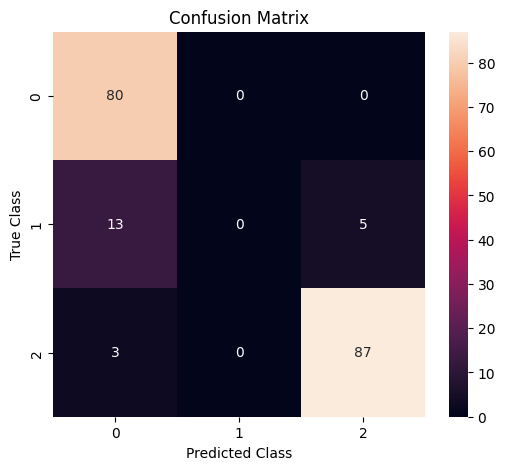

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_,


    )
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()